### Low Fidelity NN

Investigate regression fit for a non-linear function as a starting point for multi-fidelity model fitting. 


In [2]:
%reload_ext autoreload
%autoreload 2

import os
import sys
module_path = os.path.abspath(os.path.join('SurrogateModels')) # or the path to your source code
sys.path.append(module_path)
!
print(module_path)

c:\Users\troyz\GitProjects\SurrogateModeling2\SurrogateModels


In [4]:
import torch as t
import torch.nn as tnn
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from torchview import draw_graph

t.manual_seed(17)

## Doing it the Pytorch way without using our custom feature extraction
DEVICE='cpu'
DTYPE=t.float32
import numpy as np

from SurrogateModels import mfs_functions, mfsnn

# Set the random seed
t.manual_seed(17)
DEVICE='cpu'
DTYPE=t.float32

Add the low fidelity function as a data source for the model and sample it. For an initial test this uses 30 samples and 300 for the full function definition.

Define a loss function and set up the model. The initial model will have 3 hidden layers with 10 nodes and will utilize a tanh activation function that was defined in the paper "A Composite neural network that learns from multi-fidelity data: Application to funciton approximation and inverse PDE problems" Meng & Kamiadkis 2020

This neural network approach utilizes the Adam optimizer. This was the issue with the network discussed in the Q&A. It turns out the learning rate was set too small. A larger learning rate allowed the error to converge for the network.

Initialization of the model also trains the network.

In [13]:
fxn_ind = 1
hf_fxn = mfs_functions.expensive_fxn(1)
lf_fxn = mfs_functions.cheap_fxn(1)

X_lf = np.zeros([30,1])
X_lf[:,0] = np.linspace(0.0,1.0,30,endpoint=True)
y_lf = lf_fxn.evaluate(X_lf)
X_lf = t.tensor(X_lf, dtype=t.float32)
y_lf = t.tensor(y_lf, dtype=t.float32)

X_check = np.zeros([300,1])
X_check[:,0] = np.linspace(0,1.0,300,endpoint=True)
y_check = lf_fxn.evaluate(X_check)
X_check = t.tensor(X_check, dtype=t.float32)
y_check = t.tensor(y_check, dtype=t.float32)
loss = t.nn.MSELoss()
lf_model = mfsnn.MLPNetwork(X_lf,y_lf,hidden_layer_size=[20,20],activation=tnn.Tanh(),loss=loss,learning_rate=0.2,weight_decay=0.000001)

c:\Users\troyz\GitProjects\SurrogateModeling2\SurrogateModels\mfsnn.py:81: UserWarning: nn.init.xavier_uniform is now deprecated in favor of nn.init.xavier_uniform_.
  tnn.init.xavier_uniform(m.weight)


----Progress Update----
Epoch: 0 

Training Error: 0.14387831091880798 

----Progress Update----
Epoch: 10 

Training Error: 0.2717043459415436 

----Progress Update----
Epoch: 20 

Training Error: 0.07813800126314163 

----Progress Update----
Epoch: 30 

Training Error: 0.15935902297496796 

----Progress Update----
Epoch: 40 

Training Error: 0.1268405020236969 

----Progress Update----
Epoch: 50 

Training Error: 0.12615302205085754 

----Progress Update----
Epoch: 60 

Training Error: 0.1481960117816925 

----Progress Update----
Epoch: 70 

Training Error: 0.09463866055011749 

----Progress Update----
Epoch: 80 

Training Error: 0.07980469614267349 

----Progress Update----
Epoch: 90 

Training Error: 0.07650821655988693 

----Progress Update----
Epoch: 100 

Training Error: 0.05419857054948807 

----Progress Update----
Epoch: 110 

Training Error: 0.02453780546784401 

----Progress Update----
Epoch: 120 

Training Error: 0.033232953399419785 

----Progress Update----
Epoch: 130 

T

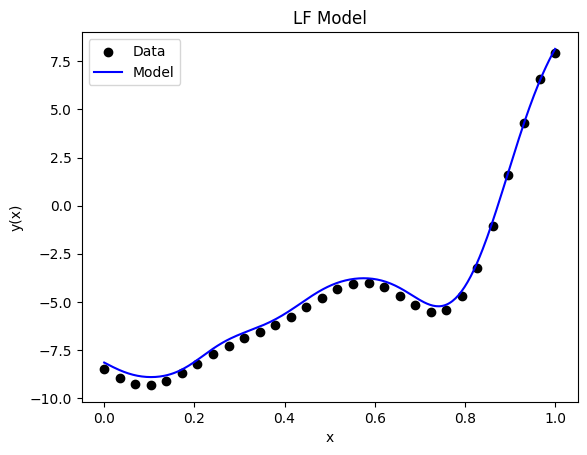

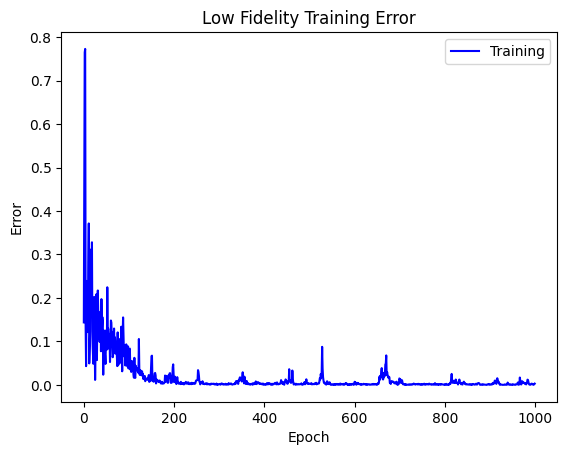

In [14]:
# Plot the results
lf_model.plot_data("Low Fidelity Model", label = "Data")
lf_model.plot_model(X_check,"LF Model", color = "blue", label="Model")
plt.show()

lf_model.plot_training_error("Low Fidelity Training Error")
plt.show()

## Multi-Fidelity Composite NN
Set-up a multi-fidelity NN and compare with test cases in Meng and Karniadakis 2020
### Smooth function fit

In [15]:
fxn_ind = 1
hf_fxn = mfs_functions.expensive_fxn(fxn_ind)
lf_fxn = mfs_functions.cheap_fxn(fxn_ind)

lf_samp = 12
X_lf = np.zeros([lf_samp,1])
X_lf[:,0] = np.linspace(0.0,1.0,lf_samp,endpoint=True)
y_lf = lf_fxn.evaluate(X_lf)
X_lf = t.tensor(X_lf, dtype=t.float32)
y_lf = t.tensor(y_lf, dtype=t.float32)

hf_samp = 4
X_hf = np.zeros([hf_samp,1])
X_hf[:,0] = np.linspace(0.0,1.0,hf_samp,endpoint=True)
y_hf = hf_fxn.evaluate(X_hf)
X_hf = t.tensor(X_hf, dtype=t.float32)
y_hf = t.tensor(y_hf, dtype=t.float32)

mfnn_model = mfsnn.MultiFidelityNN(X_lf, y_lf, X_hf, y_hf, lf_nn_dim=[20,20], hf_linear_nn_dim=[10], hf_nl_nn_dim= [10,10],lr_lf=0.2,wd_lf=0.000001,lr_mf=0.1, wd_mf=0.01)

c:\Users\troyz\GitProjects\SurrogateModeling2\SurrogateModels\mfsnn.py:81: UserWarning: nn.init.xavier_uniform is now deprecated in favor of nn.init.xavier_uniform_.
  tnn.init.xavier_uniform(m.weight)


----Progress Update----
Epoch: 0 

Training Error: 1.4876312017440796 

----Progress Update----
Epoch: 10 

Training Error: 2.520905017852783 

----Progress Update----
Epoch: 20 

Training Error: 1.3480944633483887 

----Progress Update----
Epoch: 30 

Training Error: 1.9581975936889648 

----Progress Update----
Epoch: 40 

Training Error: 0.3592544496059418 

----Progress Update----
Epoch: 50 

Training Error: 0.33927640318870544 

----Progress Update----
Epoch: 60 

Training Error: 0.016258561983704567 

----Progress Update----
Epoch: 70 

Training Error: 0.07346167415380478 

----Progress Update----
Epoch: 80 

Training Error: 0.9670138359069824 

----Progress Update----
Epoch: 90 

Training Error: 0.004883382935076952 

----Progress Update----
Epoch: 100 

Training Error: 0.27227866649627686 

----Progress Update----
Epoch: 110 

Training Error: 0.3937395513057709 

----Progress Update----
Epoch: 120 

Training Error: 0.05889461562037468 

----Progress Update----
Epoch: 130 

Train

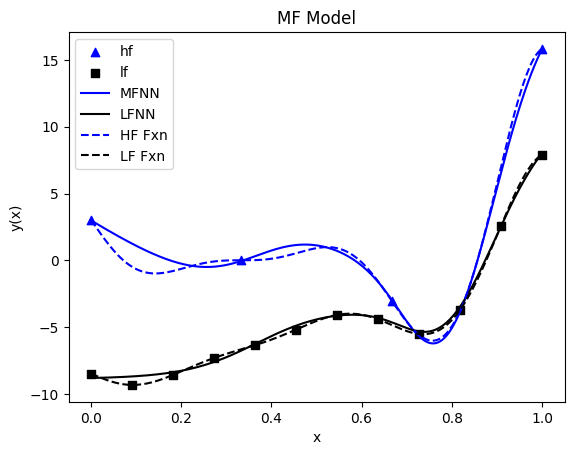

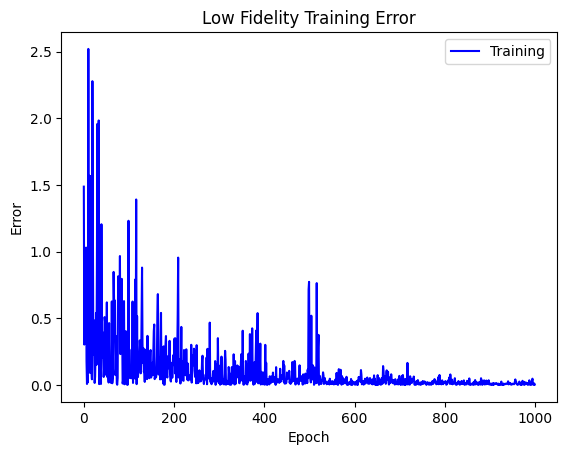

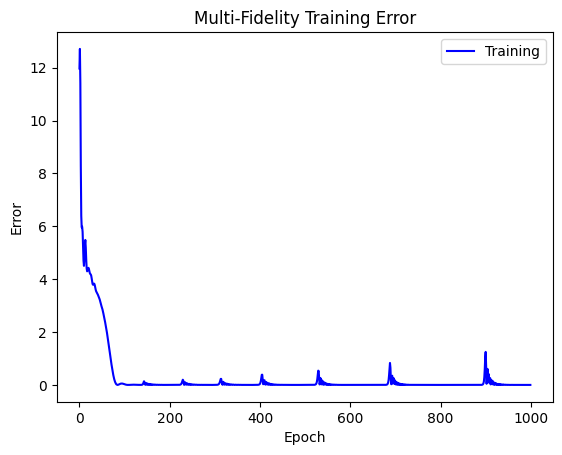

In [16]:
# Plot the results
mfnn_model.plot_data("MF Model")
X_check = np.zeros([300,1])
X_check[:,0] = np.linspace(0,1.0,300,endpoint=True)
X_check = t.tensor(X_check, dtype=t.float32)
mfnn_model.plot_model(X_check,"MF Model", color = "blue", label="MFNN")
mfnn_model.low_fidelity_nn.plot_model(X_check, name = "MF Model", label="LFNN")
hf_fxn.plot_data(name="MF Model",color = "blue", label="HF Fxn", linestyle="dashed")
lf_fxn.plot_data(name="MF Model",color = "black", label="LF Fxn", linestyle="dashed")
plt.show()

# Plot the model error
mfnn_model.low_fidelity_nn.plot_training_error("Low Fidelity Training Error")
plt.show()
mfnn_model.high_fidelity_nn.plot_training_error("Multi-Fidelity Training Error")
plt.show()